# דוכן הקינוחים של נועה
## חקירה עם צ׳טבוט, הרצה ובדיקה בגוגל קולאב

יישומי בינה מלאכותית AI • גל דנינו

זו מחברת מוכנה להתנסות ולגיבוי של ההדגמה החיה. אפשר גם לבקש מהצ׳טבוט קוד משלכם ולהשוות תוצאות. אין צורך במפתח API, בהתקנות או ב-GPU.

**לפני ההרצה:** שמרו עותק אישי של המחברת ב-Drive. הריצו את התאים לפי הסדר באמצעות כפתור ההרצה או Shift+Enter. פלט שכבר מוצג הוא תוצאה שמורה; הריצו שוב כדי לקבל תוצאה מהנתונים שלכם.

## 1. מה הבעיה?

נועה שוקלת לפתוח דוכן מארזי קינוחים ביריד:

| נתון | ערך |
|---|---:|
| מחיר למארז | 35 ₪ |
| עלות למארז | 20 ₪ |
| הוצאה קבועה | 1,000 ₪ |
| מכירות צפויות | 100 מארזים |

האם הדוכן רווחי? כמה מארזים צריך למכור כדי להגיע לאיזון? האם כדאי להוריד את המחיר?

**הנחות התרגיל:** מייצרים לפי הזמנה, אין מלאי שנותר. העלות כוללת את כל העלויות המשתנות, וההוצאה הקבועה כוללת את כל היתר. אין מסים. כל הנתונים מתייחסים ליריד אחד. הכמות היא הנחה שלנו, ולא תחזית ביקוש.

לפני השימוש בצ׳טבוט, חזו את הרווח וציינו מידע נוסף שהייתם רוצים לדעת.

## 2. חקרו גישות בעזרת הצ׳טבוט

העתיקו לשיחה:

> אנחנו רוצים לעזור לנועה להחליט אם לפתוח דוכן קינוחים. מחיר למארז 35 ₪, עלות למארז 20 ₪, הוצאה קבועה 1,000 ₪ וכמות צפויה 100. מייצרים לפי הזמנה ואין הוצאות נוספות. אין לנו ידע מוקדם בתכנות. שאל אותנו שאלות הבהרה, ואז הצע כמה גישות לפתרון, מהפשוטה למורכבת. הסבר מה כל גישה דורשת, מה היתרונות והמגבלות ומה אי אפשר לדעת מהנתונים. אל תניח מראש שצריך לכתוב קוד.

בהמשך שאלו:

> אם נבחר קוד Python בגוגל קולאב, מה התפקיד של כל כלי? מה צריך לדעת כדי להתחיל? הסבר בצעדים קצרים ותן ניסיון ראשון שאפשר לבדוק.

לתרגיל המשותף נבחר Python בקולאב. בפרויקט שלכם אפשר לבחור דרך אחרת בהתאם לבעיה ולמשתמש.

## 3. בקשה ליצירת קוד

> כתוב קוד Python לתא בגוגל קולאב, ללא התקנות או שירותים חיצוניים. אפשר לשנות מחיר ליחידה, עלות ליחידה, הוצאה קבועה וכמות. חשב הכנסות, עלות כוללת, רווח ונקודת איזון ביחידות שלמות. הפרד בין החישוב להצגת התוצאות. בדוק שהערכים מספריים, סופיים ולא שליליים ושהכמות שלמה. אם ההוצאה הקבועה חיובית והמחיר קטן מהעלות ליחידה או שווה לה, הסבר שאין נקודת איזון סופית. החזר קוד מלא והסבר איך להריץ אותו. אל תציג תחזית ביקוש.

התא הבא מכיל גרסה מוכנה. הריצו אותו פעם אחת כדי להגדיר את החישוב.

In [1]:
import math
from numbers import Real

def calculate_stall(price, unit_cost, fixed_cost, quantity):
    """חישוב תרחיש עסקי. הכמות היא הנחה ולא חיזוי."""
    values = {"מחיר": price, "עלות ליחידה": unit_cost,
              "הוצאה קבועה": fixed_cost, "כמות": quantity}
    for name, value in values.items():
        if isinstance(value, bool) or not isinstance(value, Real):
            raise ValueError(f"{name}: נדרש מספר")
        if not math.isfinite(value) or value < 0:
            raise ValueError(f"{name}: נדרש מספר סופי ולא שלילי")
    if quantity != int(quantity):
        raise ValueError("כמות: נדרש מספר שלם")
    quantity = int(quantity)
    revenue = price * quantity
    total_cost = fixed_cost + unit_cost * quantity
    contribution = price - unit_cost
    if fixed_cost == 0:
        break_even = 0  # באפס מכירות הרווח אפס; ייתכן הפסד בכמות חיובית
    elif contribution <= 0:
        break_even = None
    else:
        break_even = math.ceil(fixed_cost / contribution)
    return {"revenue": revenue, "total_cost": total_cost,
            "profit": revenue - total_cost, "break_even": break_even,
            "contribution": contribution}

def show_result(result):
    print(f"הכנסות: {result['revenue']:,.2f} ₪")
    print(f"עלות כוללת: {result['total_cost']:,.2f} ₪")
    print(f"רווח: {result['profit']:,.2f} ₪")
    if result['profit'] > 0:
        print("הדוכן רווחי בתרחיש שהוזן.")
    elif result['profit'] == 0:
        print("בתרחיש שהוזן ההכנסות מכסות בדיוק את העלויות.")
    else:
        print("הדוכן מפסיד בתרחיש שהוזן.")
    if result['break_even'] is None:
        print("אין נקודת איזון סופית: התרומה ליחידה אינה חיובית.")
    else:
        print(f"מספר היחידות המינימלי לרווח לא שלילי: {result['break_even']}")
        if result['contribution'] < 0:
            print("שימו לב: כל מכירה מוסיפה הפסד; איזון באפס יחידות בלבד.")

print("החישוב מוכן. המשיכו לתא הבא.")

החישוב מוכן. המשיכו לתא הבא.


## 4. שנו נתונים והריצו

שנו את ארבעת הערכים בתא או בטופס של קולאב, חזו את התוצאה והריצו שוב. אם מתקבלת הודעה שהפונקציה אינה מוגדרת, הריצו קודם את תא החישוב.

In [2]:
# @title מחשבון דוכן קינוחים
price = 35.0 # @param {type:"number"}
unit_cost = 20.0 # @param {type:"number"}
fixed_cost = 1000.0 # @param {type:"number"}
quantity = 100 # @param {type:"integer"}

try:
    result = calculate_stall(price, unit_cost, fixed_cost, quantity)
    show_result(result)
except ValueError as error:
    print(f"בדקו את הנתונים: {error}")

הכנסות: 3,500.00 ₪
עלות כוללת: 3,000.00 ₪
רווח: 500.00 ₪
הדוכן רווחי בתרחיש שהוזן.
מספר היחידות המינימלי לרווח לא שלילי: 67


## 5. בדקו את התוצאה

הניחו עלות 20 ₪ והוצאה קבועה 1,000 ₪ בכל השורות:

| מחיר | כמות | רווח צפוי | כמות מינימלית לאיזון |
|---:|---:|---:|---:|
| 35 | 100 | 500 ₪ | 67 |
| 35 | 66 | ‎-10 ₪ | 67 |
| 35 | 67 | 5 ₪ | 67 |
| 30 | 100 | 0 ₪ | 100 |
| 30 | 150 | 500 ₪ | 100 |
| 35 | 0 | ‎-1,000 ₪ | 67 |
| 20 | 100 | ‎-1,000 ₪ | אין איזון סופי |

בדקו גם כמות שלילית, כמות 2.5 וערך שאינו מספר. בדיקת מחרוזת צריכה להיכתב בקוד בתוך מרכאות, למשל `"abc"`.

**לתרגול בכיתה:** נסו את בדיקת הבסיס ועוד תרחישים, כולל קלט לא תקין. חזו תוצאה והשוו לפלט. המחברת מיועדת ללמידה ולהתנסות; אין צורך להגיש אותה או את הבדיקות.

In [3]:
# דוגמת בדיקת קלט לא תקין
try:
    calculate_stall(35, 20, 1000, "abc")
except ValueError as error:
    print(f"השגיאה הצפויה התקבלה: {error}")

השגיאה הצפויה התקבלה: כמות: נדרש מספר


## 6. רווח מול כמות מכירות

הגרף משווה מחירים של 35 ו-30 ₪, כשהעלות היא 20 ₪ וההוצאה הקבועה 1,000 ₪. לפני ההרצה חזו: איזה קו יהיה תלול יותר? היכן יגיע כל אחד לרווח אפס?

הכיתובים בגרף באנגלית לשם קריאות בסביבות שונות. הגרף מתאר תרחישים, ואינו מנבא כמה לקוחות יקנו.

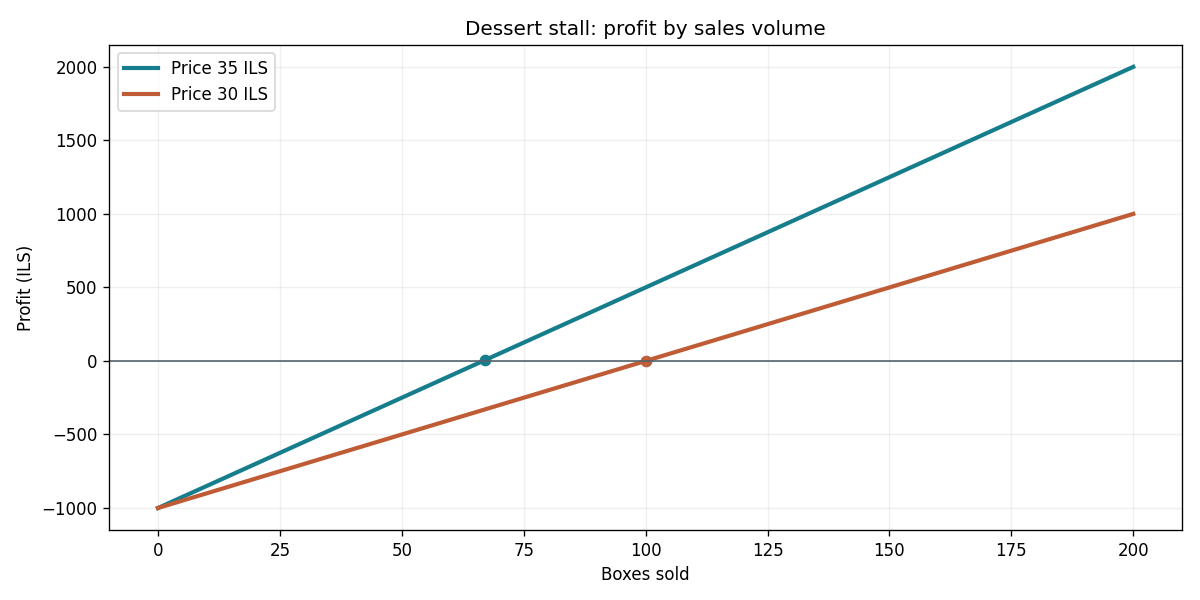

In [4]:
import matplotlib.pyplot as plt

quantities = list(range(201))
fig, ax = plt.subplots(figsize=(10, 5))
for scenario_price, color in [(35, "#167D8D"), (30, "#C05C35")]:
    profits = [calculate_stall(scenario_price, 20, 1000, q)["profit"]
               for q in quantities]
    ax.plot(quantities, profits, label=f"Price {scenario_price} ILS", color=color, linewidth=2.5)
    threshold = calculate_stall(scenario_price, 20, 1000, 0)["break_even"]
    ax.scatter([threshold], [calculate_stall(scenario_price, 20, 1000, threshold)["profit"]], color=color)
ax.axhline(0, color="#53636D", linewidth=1)
ax.set(title="Dessert stall: profit by sales volume", xlabel="Boxes sold", ylabel="Profit (ILS)")
ax.grid(alpha=0.2)
ax.legend()
fig.tight_layout()
plt.show()

## 7. איך אחרים יוכלו להשתמש?

העתיקו לצ׳טבוט:

> יש לנו מחשבון שעובד ב-Python בקולאב. המשתמש שלנו הוא בעל דוכן בלי ניסיון בתכנות. הצע שתי דרכים להנגיש לו את הפתרון, למשל מחברת משותפת או ממשק אחר. הסבר מה המשתמש צריך לעשות, אילו חשבונות והרשאות נדרשים, מה עולה כסף ומה עדיין צריך להכין. המלץ על דרך ראשונית לפי האילוצים שלנו. אם צריך מידע עדכני, חפש אותו או ציין מה לא אומת.

תארו מסלול שימוש קצר. שיתוף מחברת אינו מבטיח שמישהו יודע להפעיל אותה. אם ניסיתם שיתוף, בקשו מאדם אחר לבצע משימה לפי ההוראות בלבד ותעדו היכן נעצר. אל תכללו סודות או מידע אישי במחברת משותפת.

בשלב זה נדרשת תוכנית הנגשה; אין חובה לפרסם יישום מלא.

## 8. בדיקה אוטומטית של המחשבון - רשות

התא הבא שולח לפונקציה `calculate_stall` כמה דוגמאות עם תשובות ידועות. הוא משווה את **הרווח ואת נקודת האיזון שהפונקציה החזירה** לתוצאות הצפויות, ומציג לכל דוגמה אם הבדיקה עברה.

**איך משתמשים?** הריצו קודם את תא הגדרת החישוב בסעיף 3, ואז את התא כאן. אין צורך להקליד נתונים או לערוך את התא. הוא משתמש בנתוני בדיקה קבועים, ולא בארבעת הערכים שבחרתם בסעיף 4.

**איך קוראים את הפלט?** לדוגמה, במחיר 35 ובכמות 100 צפוי רווח 500 ואיזון ב-67 יחידות. אם התקבלו התוצאות האלה תופיע ההודעה "עבר". אחרת תופיע "נדרש תיקון", לצד התוצאה הצפויה והתוצאה שהתקבלה. אפשר לשלוח את השורה לצ׳טבוט ולבקש הסבר ותיקון.

בסוף נבדק גם שהמחשבון דוחה קלט לא תקין. הבדיקות מתייחסות לפונקציה שהוגדרה במחברת זו; אם כתבתם קוד אחר, בקשו מהצ׳טבוט להתאים את הבדיקות אליו. מעבר של הדוגמאות האלה אינו מבטיח שאין שגיאות נוספות.

זהו כלי עזר להמחשת בדיקת קוד, לא משימה להגשה.

In [5]:
cases = [
    ("תרחיש בסיס", (35, 20, 1000, 100), 500, 67),
    ("מתחת לאיזון", (35, 20, 1000, 66), -10, 67),
    ("מעל לאיזון", (35, 20, 1000, 67), 5, 67),
    ("מחיר מוזל", (30, 20, 1000, 100), 0, 100),
    ("מחיר מוזל ומכירות מוגברות", (30, 20, 1000, 150), 500, 100),
    ("ללא מכירות", (35, 20, 1000, 0), -1000, 67),
    ("מחיר שווה לעלות", (20, 20, 1000, 100), -1000, None),
]
passed = 0
for label, inputs, expected_profit, expected_threshold in cases:
    try:
        actual = calculate_stall(*inputs)
        ok = (actual["profit"] == expected_profit
              and actual["break_even"] == expected_threshold)
        passed += int(ok)
        print(f"{label}: {'עבר' if ok else 'נדרש תיקון'}")
        print(f"  צפוי: רווח {expected_profit}, איזון {expected_threshold}")
        print(f"  התקבל: רווח {actual['profit']}, איזון {actual['break_even']}")
    except Exception as error:
        print(f"{label}: נדרש תיקון - {error}")

invalid_cases = [-1, 2.5, "abc", None, float("nan"), float("inf"), True]
rejected = 0
for invalid in invalid_cases:
    try:
        calculate_stall(35, 20, 1000, invalid)
    except ValueError:
        rejected += 1
    except Exception as error:
        print(f"בדיקת קלט {invalid}: התקבלה שגיאה בלתי צפויה - {error}")

print(f"סיכום: {passed} מתוך {len(cases)} תרחישים עברו.")
print(f"{rejected} מתוך {len(invalid_cases)} קלטים לא תקינים נדחו כצפוי.")
print("None בשדה האיזון פירושו שאין נקודת איזון סופית.")

תרחיש בסיס: עבר
  צפוי: רווח 500, איזון 67
  התקבל: רווח 500, איזון 67
מתחת לאיזון: עבר
  צפוי: רווח -10, איזון 67
  התקבל: רווח -10, איזון 67
מעל לאיזון: עבר
  צפוי: רווח 5, איזון 67
  התקבל: רווח 5, איזון 67
מחיר מוזל: עבר
  צפוי: רווח 0, איזון 100
  התקבל: רווח 0, איזון 100
מחיר מוזל ומכירות מוגברות: עבר
  צפוי: רווח 500, איזון 100
  התקבל: רווח 500, איזון 100
ללא מכירות: עבר
  צפוי: רווח -1000, איזון 67
  התקבל: רווח -1000, איזון 67
מחיר שווה לעלות: עבר
  צפוי: רווח -1000, איזון None
  התקבל: רווח -1000, איזון None
סיכום: 7 מתוך 7 תרחישים עברו.
7 מתוך 7 קלטים לא תקינים נדחו כצפוי.
None בשדה האיזון פירושו שאין נקודת איזון סופית.


## 9. מה למדתם מההתנסות?

נסו להסביר במילים שלכם: איך מחושב הרווח? מהי נקודת האיזון? מה אפשר לדעת מהחישוב ומה עדיין תלוי בהנחות עסקיות? אם משהו אינו ברור, שאלו את הצ׳טבוט ונסו דוגמה נוספת.

**אין חובת הגשה של המחברת, הקוד או תיעוד הבדיקות.** אפשר לשמור עותק לעצמכם ולהמשיך להתנסות.

ההגשה הצוותית מתייחסת לפרויקט שלכם: הבעיה, הגישות שחקרתם, בחירת כלים, ניסיון ראשון ותוכנית הנגשה לאחרים. הוראותיה מופיעות בדף השיעור ובאתר הקורס.